In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
import joblib, shap

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, VotingClassifier)
from xgboost import XGBClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve, f1_score, recall_score, precision_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [ ]:
import numpy as np, pandas as pd

# Removed after testing (no loss in cross-validated performance): gender, Partner, DeviceProtection,
# OnlineBackup, StreamingTV, StreamingMovies. See the feature-selection note in the notebook.
SERVICE_COLS = ["OnlineSecurity", "TechSupport"]     # the add-ons we keep

NUM_COLS = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_spend",
            "charge_gap", "num_support_services", "is_month_to_month", "autopay"]

CAT_COLS = ["Dependents", "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "TechSupport", "Contract", "PaperlessBilling",
            "PaymentMethod", "tenure_group"]

# The raw columns a customer record must contain (the app and batch upload check for these)
REQUIRED_COLUMNS = ["SeniorCitizen", "Dependents", "tenure", "PhoneService", "MultipleLines",
                    "InternetService", "OnlineSecurity", "TechSupport", "Contract",
                    "PaperlessBilling", "PaymentMethod", "MonthlyCharges", "TotalCharges"]

def prepare(X):
    """Raw customer rows in, model-ready columns out. Runs identically at train and predict time."""
    X = X.copy()
    X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce").fillna(0)
    X = X.replace({"No internet service": "No", "No phone service": "No"})
    X["avg_monthly_spend"] = (X["TotalCharges"] / X["tenure"].replace(0, np.nan)).fillna(X["MonthlyCharges"])
    X["charge_gap"] = X["MonthlyCharges"] - X["avg_monthly_spend"]
    X["num_support_services"] = (X[SERVICE_COLS] == "Yes").sum(axis=1)
    X["is_month_to_month"] = (X["Contract"] == "Month-to-month").astype(int)
    X["autopay"] = X["PaymentMethod"].str.contains("automatic", case=False).astype(int)
    X["tenure_group"] = pd.cut(X["tenure"], [-1, 12, 24, 48, 1000],
                               labels=["0-12", "13-24", "25-48", "49+"]).astype(str)
    return X

Overwriting features.py


In [3]:
from features import prepare, NUM_COLS, CAT_COLS, SERVICE_COLS, REQUIRED_COLUMNS

## 2. Load and clean

In [4]:
PATH = "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"   # change if your file is elsewhere
df = pd.read_csv(PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df = df.drop(columns="customerID")

# TotalCharges is text because 11 rows are blank. Check why before choosing a fix.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank = df["TotalCharges"].isna()
print("Blank TotalCharges:", blank.sum(), "| all of them have tenure == 0:", (df.loc[blank, "tenure"] == 0).all())

# Those customers have not been billed yet, so 0 is the correct value (no rows are thrown away).
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", int(df.isna().sum().sum()))
print(f"Churn rate: {df['Churn'].mean():.1%}")

Blank TotalCharges: 11 | all of them have tenure == 0: True
Duplicate rows: 22
Missing values: 0
Churn rate: 26.5%


## 3. Exploratory analysis

In [6]:
eda = df.assign(Churn=df["Churn"].map({1: "Yes", 0: "No"}))

fig = px.pie(eda, names="Churn", hole=0.45, title="<b>Churn distribution</b>")
fig.update_traces(textinfo="percent+label", textfont_size=16)
fig.show()

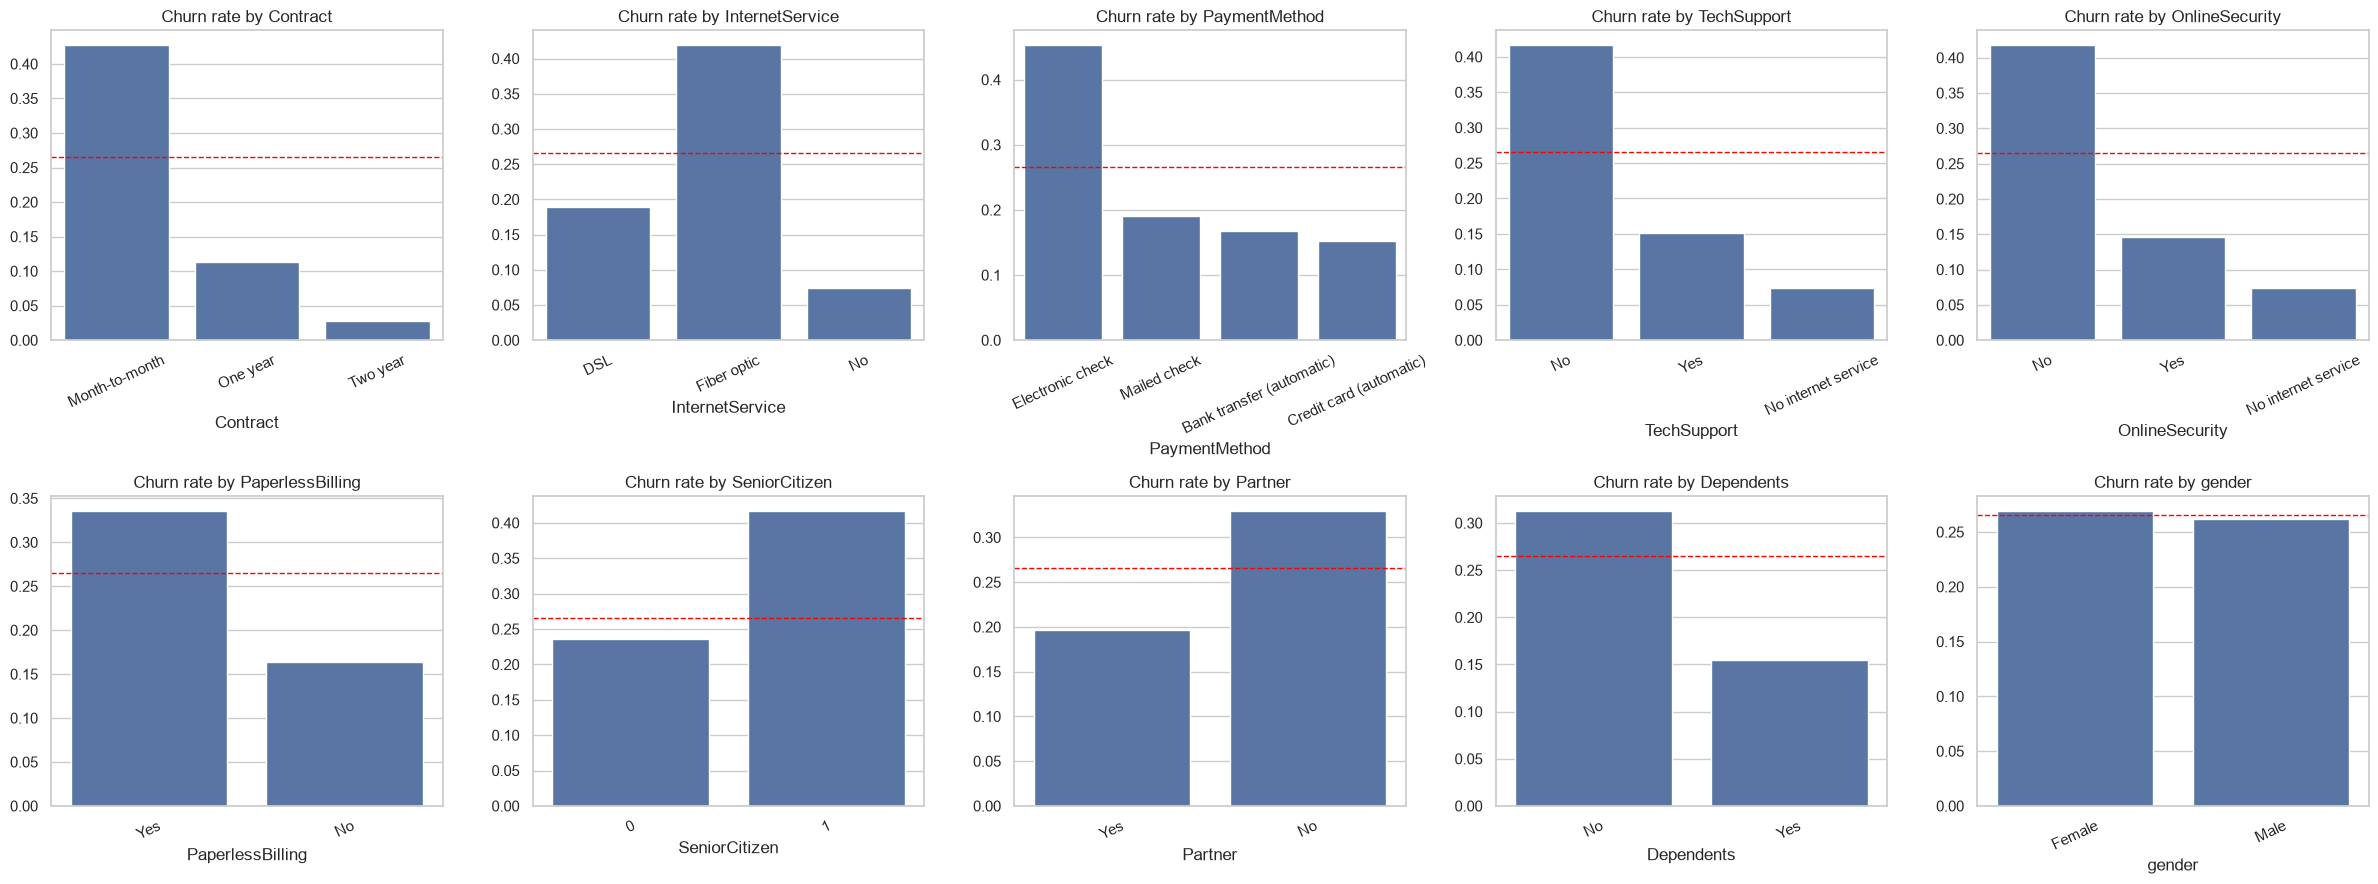

In [7]:
# Churn RATE per category (more honest than raw counts, because group sizes differ)
cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity",
        "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents", "gender"]
fig, axes = plt.subplots(2, 5, figsize=(24, 9))
for ax, c in zip(axes.ravel(), cols):
    sns.barplot(data=df, x=c, y="Churn", errorbar=None, ax=ax, color="#4C72B0")
    ax.set_title(f"Churn rate by {c}"); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.axhline(df["Churn"].mean(), color="red", ls="--", lw=1)
plt.tight_layout(); plt.show()

In [8]:
fig = px.histogram(eda, x="Churn", color="Contract", barmode="group", title="<b>Churn by contract type</b>")
fig.update_layout(width=700, height=450, bargap=0.2); fig.show()

fig = px.histogram(eda, x="Churn", color="PaymentMethod", barmode="group", title="<b>Churn by payment method</b>")
fig.update_layout(width=800, height=450, bargap=0.2); fig.show()

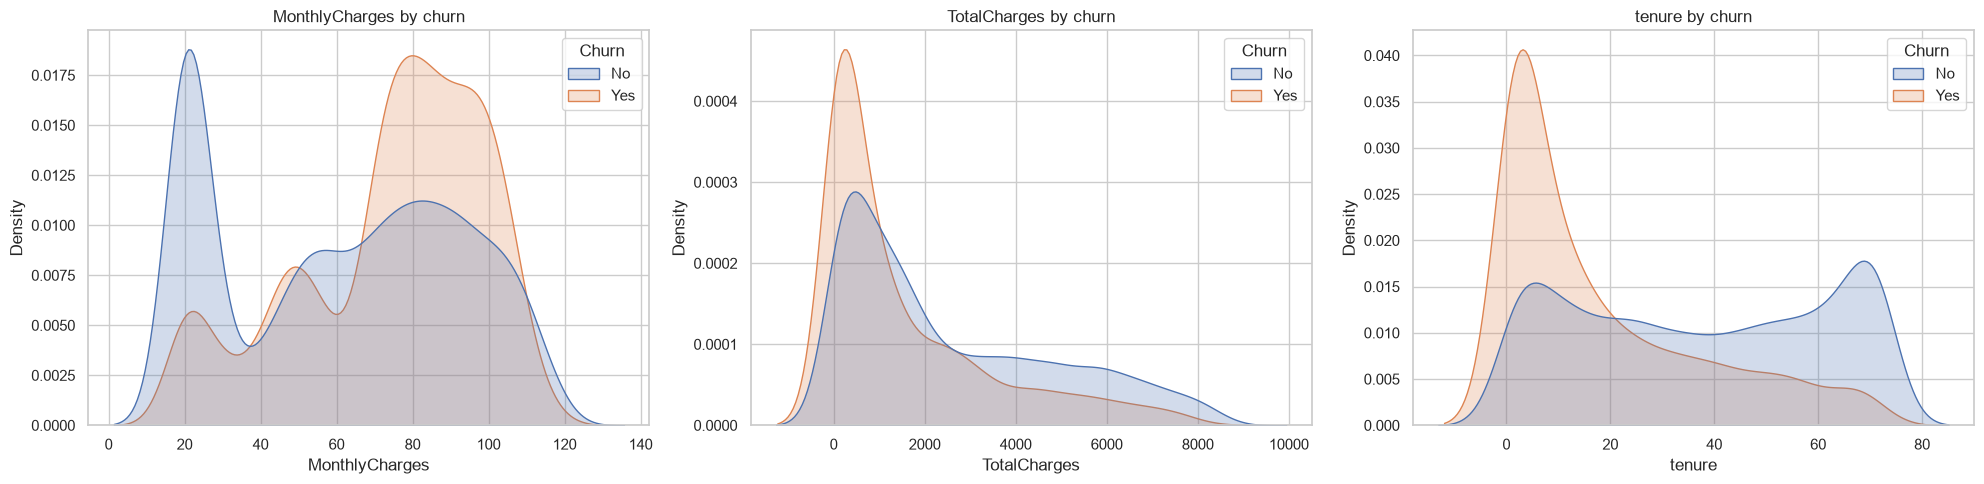

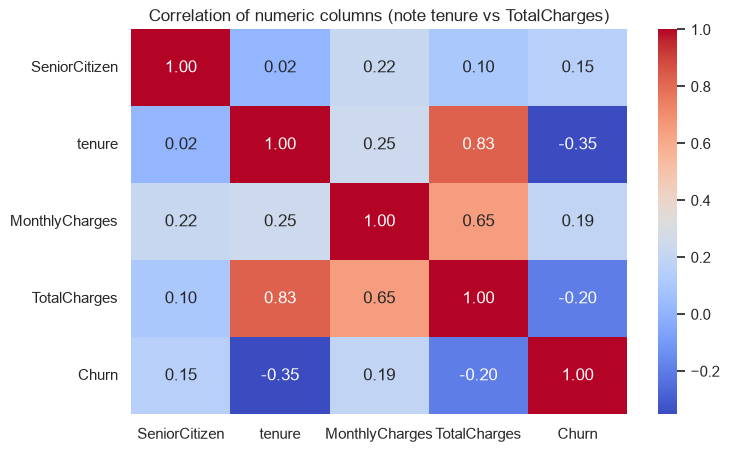

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, c in zip(axes, ["MonthlyCharges", "TotalCharges", "tenure"]):
    sns.kdeplot(data=eda, x=c, hue="Churn", fill=True, common_norm=False, ax=ax)
    ax.set_title(f"{c} by churn")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation of numeric columns (note tenure vs TotalCharges)"); plt.show()

### EDA findings (check these against your own plots)
1. **Contract type is the strongest signal:** month-to-month customers churn far more than one- or two-year contracts.
2. **New customers churn most:** churn is concentrated in the first year of tenure.
3. **Fiber optic and electronic-check customers** churn above the average rate; customers with TechSupport / OnlineSecurity churn less.
4. **Gender barely matters** (bars are nearly equal), and `tenure` and `TotalCharges` are strongly correlated, which matters for linear models.

## 4. Split first, then build the pipeline

The holdout set is touched exactly once, at the end. Everything else (model choice, tuning, threshold) uses cross-validation on the training set.

In [10]:
X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, f"train churn {y_train.mean():.3f} | test churn {y_test.mean():.3f}")

def make_pipe(clf):
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])
    return Pipeline([("prep", FunctionTransformer(prepare)), ("pre", pre), ("clf", clf)])

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

(5634, 19) (1409, 19) train churn 0.265 | test churn 0.265


## 5. Compare models with stratified cross-validation

Ranked by **PR-AUC**, because churn is the minority class. Recall and F1 here use the default 0.5 cutoff, so models without class weighting (AdaBoost, Gradient Boosting, KNN, Naive Bayes) look weak on recall; the threshold step later addresses that.

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN (k=25)": KNeighborsClassifier(n_neighbors=25),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Kernel SVM": SVC(class_weight="balanced", random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(scale_pos_weight=pos_weight, eval_metric="aucpr", random_state=RANDOM_STATE),
}
models["Voting (LR+RF+GB)"] = VotingClassifier(
    [("lr", models["Logistic Regression"]), ("rf", models["Random Forest"]), ("gb", models["Gradient Boosting"])],
    voting="soft")

scoring = ["roc_auc", "average_precision", "recall", "f1", "accuracy"]
rows, fold_auc = [], {}
t0 = time.time()
for name, clf in models.items():
    res = cross_validate(make_pipe(clf), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    fold_auc[name] = res["test_roc_auc"]
    rows.append({"Model": name,
                 "ROC-AUC": res["test_roc_auc"].mean(), "ROC-AUC std": res["test_roc_auc"].std(),
                 "PR-AUC": res["test_average_precision"].mean(),
                 "Recall": res["test_recall"].mean(), "F1": res["test_f1"].mean(),
                 "Accuracy": res["test_accuracy"].mean()})
    print(f"done {name:22s} ({time.time()-t0:.0f}s)")

results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
results.round(3)

done Logistic Regression    (3s)
done KNN (k=25)             (5s)
done Naive Bayes            (5s)
done Decision Tree          (6s)
done Random Forest          (8s)
done Kernel SVM             (10s)
done AdaBoost               (10s)
done Gradient Boosting      (12s)
done XGBoost                (12s)
done Voting (LR+RF+GB)      (16s)


,Model,ROC-AUC,ROC-AUC std,PR-AUC,Recall,F1,Accuracy
0,Voting (LR+RF+GB),0.849,0.012,0.666,0.708,0.641,0.790
1,Logistic Regression,0.846,0.011,0.663,0.799,0.628,0.749
2,Random Forest,0.845,0.010,0.659,0.761,0.632,0.765
3,Gradient Boosting,0.845,0.013,0.654,0.510,0.575,0.800
4,AdaBoost,0.845,0.011,0.644,0.526,0.584,0.801
5,Naive Bayes,0.834,0.011,0.626,0.781,0.623,0.749
6,XGBoost,0.821,0.007,0.614,0.643,0.596,0.769
7,KNN (k=25),0.830,0.005,0.613,0.553,0.589,0.796
8,Decision Tree,0.826,0.007,0.609,0.809,0.610,0.725
9,Kernel SVM,0.826,0.012,0.599,0.781,0.622,0.748


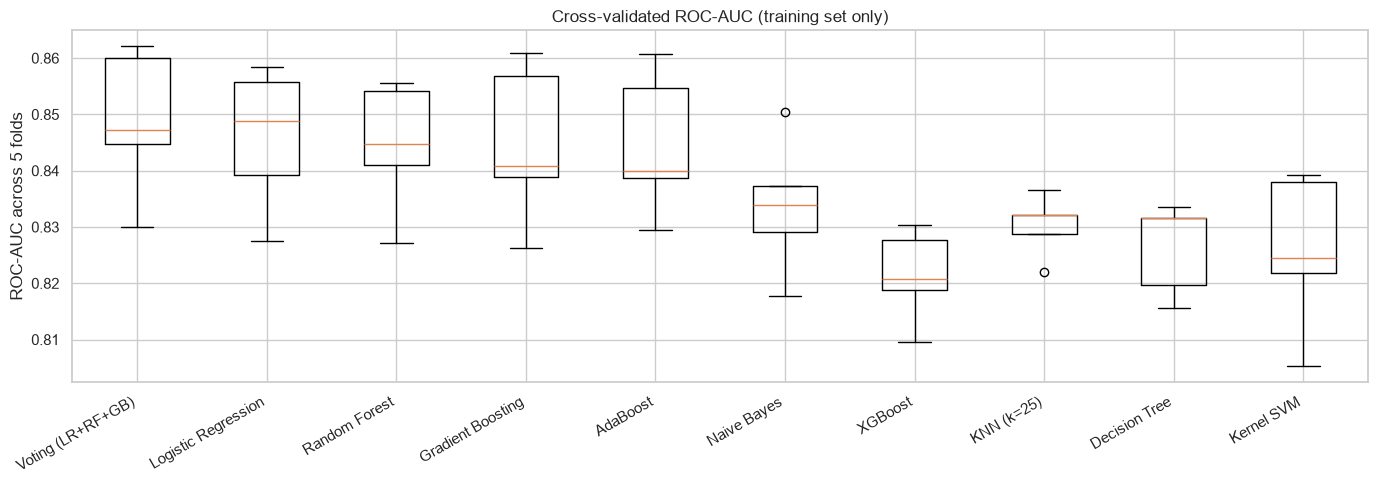

In [12]:
order = results["Model"].tolist()
plt.figure(figsize=(14, 5))
plt.boxplot([fold_auc[m] for m in order])
plt.xticks(range(1, len(order) + 1), order, rotation=30, ha="right"); plt.ylabel("ROC-AUC across 5 folds")
plt.title("Cross-validated ROC-AUC (training set only)"); plt.tight_layout(); plt.show()

Most models land within a narrow band, so the differences are small compared with the fold-to-fold spread. That is normal for this dataset: a simple, interpretable model is often almost as good as a boosted one.

## 6. Tune XGBoost

XGBoost is tuned here because boosted trees are usually strongest on tabular data and it integrates well with SHAP. **If another model clearly wins the table above, swap it in** (change the estimator and parameter grid).

In [13]:
param_dist = {
    "clf__n_estimators": [200, 400, 600],
    "clf__max_depth": [2, 3, 4, 5],
    "clf__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "clf__subsample": [0.7, 0.85, 1.0],
    "clf__colsample_bytree": [0.7, 0.85, 1.0],
    "clf__min_child_weight": [1, 3, 5],
}
search = RandomizedSearchCV(
    make_pipe(XGBClassifier(scale_pos_weight=pos_weight, eval_metric="aucpr", random_state=RANDOM_STATE)),
    param_dist, n_iter=25, scoring="average_precision", cv=cv,
    n_jobs=-1, random_state=RANDOM_STATE, verbose=1)
search.fit(X_train, y_train)
best = search.best_estimator_
print("Best CV PR-AUC:", round(search.best_score_, 4))
print(search.best_params_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best CV PR-AUC: 0.6638
{'clf__subsample': 0.85, 'clf__n_estimators': 400, 'clf__min_child_weight': 5, 'clf__max_depth': 4, 'clf__learning_rate': 0.01, 'clf__colsample_bytree': 0.7}


## 7. Choose the decision threshold from business cost

Out-of-fold predictions on the **training** set pick the threshold, so the holdout stays clean. The three cost numbers below are **assumptions**: change them and the threshold changes. State them in your README.

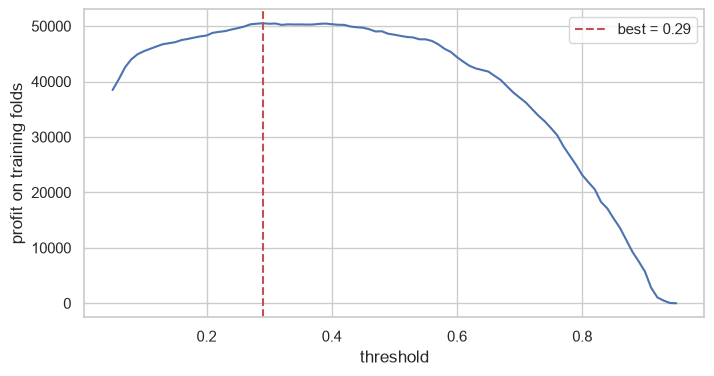

Chosen threshold: 0.29 | profit at 0.50: 48450 | at chosen: 50510


In [14]:
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

COST_OFFER  = 10    # cost of one retention offer
VALUE_SAVED = 200   # value of keeping a customer who would have churned
SAVE_RATE   = 0.30  # share of contacted churners the offer actually retains

def profit(th, proba, y_true):
    contacted = proba >= th
    caught = (contacted & (np.asarray(y_true) == 1)).sum()
    return caught * SAVE_RATE * VALUE_SAVED - contacted.sum() * COST_OFFER

ths = np.linspace(0.05, 0.95, 91)
profits = [profit(t, oof, y_train) for t in ths]
best_th = float(ths[int(np.argmax(profits))])

plt.figure(figsize=(8, 4))
plt.plot(ths, profits); plt.axvline(best_th, color="r", ls="--", label=f"best = {best_th:.2f}")
plt.xlabel("threshold"); plt.ylabel("profit on training folds"); plt.legend(); plt.show()
print(f"Chosen threshold: {best_th:.2f} | profit at 0.50: {profit(0.5, oof, y_train):.0f} | at chosen: {max(profits):.0f}")

## 8. Final evaluation on the holdout (run once)

In [15]:
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= best_th).astype(int)

# Is the tuned model actually better than a simple baseline?
base = make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X_train, y_train)
base_proba = base.predict_proba(X_test)[:, 1]

summary = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test, proba), roc_auc_score(y_test, base_proba)],
    "PR-AUC": [average_precision_score(y_test, proba), average_precision_score(y_test, base_proba)],
}, index=["Tuned XGBoost", "Logistic baseline"]).round(3)
display(summary)

print(f"Tuned model at threshold {best_th:.2f}")
print(classification_report(y_test, pred, target_names=["Stay", "Churn"]))

,ROC-AUC,PR-AUC
Tuned XGBoost,0.847,0.662
Logistic baseline,0.842,0.638


Tuned model at threshold 0.29
              precision    recall  f1-score   support

        Stay       0.95      0.56      0.71      1035
       Churn       0.43      0.92      0.59       374

    accuracy                           0.66      1409
   macro avg       0.69      0.74      0.65      1409
weighted avg       0.81      0.66      0.67      1409



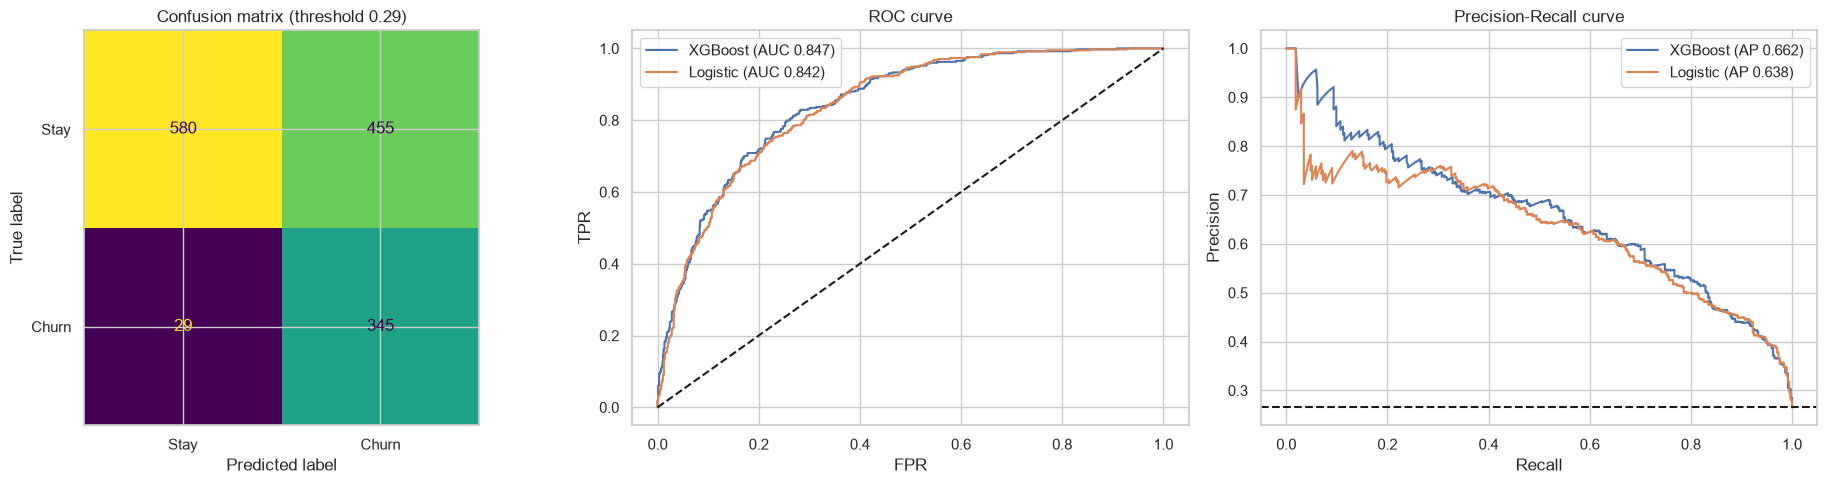

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Churn"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title(f"Confusion matrix (threshold {best_th:.2f})")

for p, n in [(proba, "XGBoost"), (base_proba, "Logistic")]:
    fpr, tpr, _ = roc_curve(y_test, p); ax[1].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_test, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curve"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()

for p, n in [(proba, "XGBoost"), (base_proba, "Logistic")]:
    pr, rc, _ = precision_recall_curve(y_test, p); ax[2].plot(rc, pr, label=f"{n} (AP {average_precision_score(y_test, p):.3f})")
ax[2].axhline(y_test.mean(), color="k", ls="--"); ax[2].set_title("Precision-Recall curve"); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].legend()
plt.tight_layout(); plt.show()

,churners,churn_rate,cum_capture
decile,,,
1,106,0.752,0.283
2,88,0.624,0.519
3,59,0.418,0.676
4,46,0.326,0.799
5,27,0.191,0.872
6,23,0.164,0.933
7,12,0.085,0.965
8,10,0.071,0.992
9,2,0.014,0.997


Contacting the riskiest 20% of customers reaches 52% of all churners.


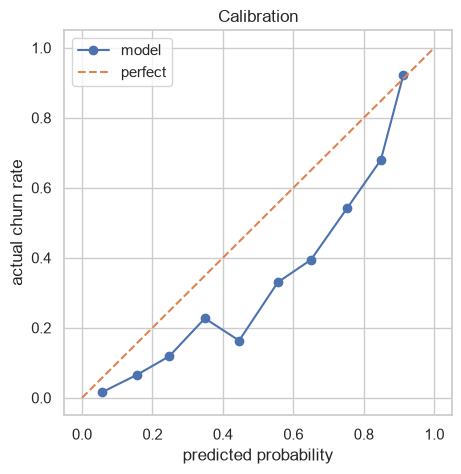

In [17]:
# Lift / gain: how many churners do we catch by contacting the riskiest customers first?
r = pd.DataFrame({"y": y_test.values, "p": proba}).sort_values("p", ascending=False).reset_index(drop=True)
r["decile"] = pd.qcut(r.index, 10, labels=range(1, 11))
gain = r.groupby("decile", observed=True)["y"].agg(["sum", "mean"]).rename(columns={"sum": "churners", "mean": "churn_rate"})
gain["cum_capture"] = gain["churners"].cumsum() / r["y"].sum()
display(gain.round(3))
top20 = r.head(int(len(r) * 0.2))
print(f"Contacting the riskiest 20% of customers reaches {top20['y'].sum() / r['y'].sum():.0%} of all churners.")

# Calibration
frac, mean_p = calibration_curve(y_test, proba, n_bins=10)
plt.figure(figsize=(5, 5)); plt.plot(mean_p, frac, marker="o", label="model"); plt.plot([0, 1], [0, 1], "--", label="perfect")
plt.xlabel("predicted probability"); plt.ylabel("actual churn rate"); plt.title("Calibration"); plt.legend(); plt.show()

**Calibration note:** `scale_pos_weight` pushes predicted probabilities upward, so they are good for *ranking* customers but should not be quoted as literal percentages. If you need true probabilities, wrap the model in `CalibratedClassifierCV`.

## 9. Explain the model with SHAP

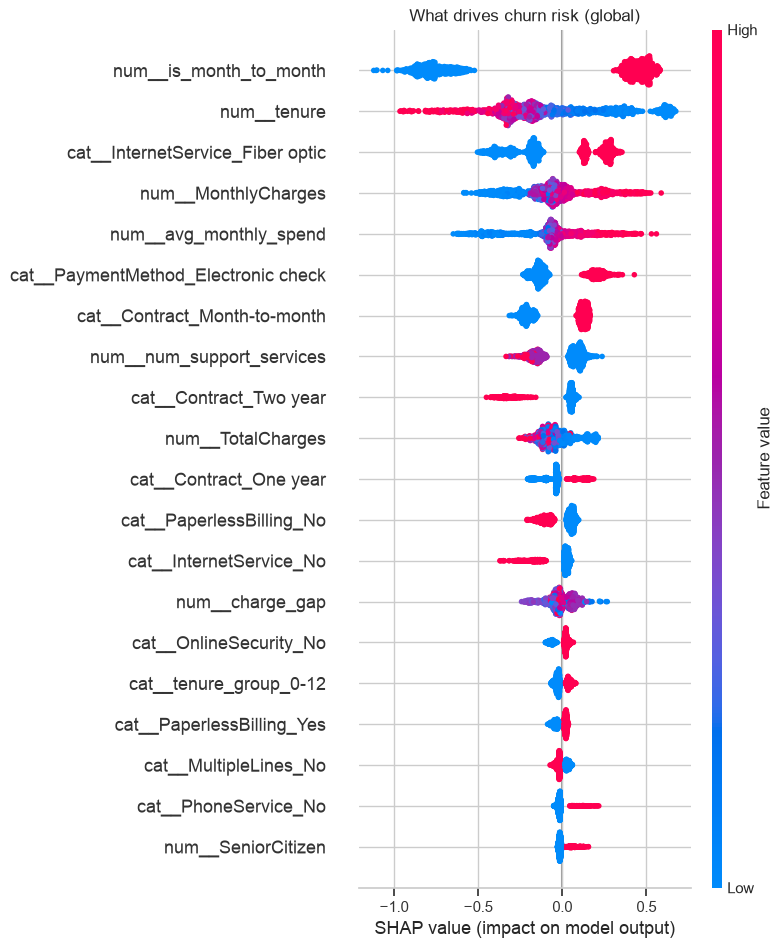

,mean |SHAP|
num__is_month_to_month,0.595
num__tenure,0.307
cat__InternetService_Fiber optic,0.243
num__MonthlyCharges,0.173
num__avg_monthly_spend,0.167
cat__PaymentMethod_Electronic check,0.166
cat__Contract_Month-to-month,0.166
num__num_support_services,0.124
cat__Contract_Two year,0.119
num__TotalCharges,0.084


In [18]:
pre = best.named_steps["pre"]
Xt = pre.transform(best.named_steps["prep"].transform(X_test))
names = pre.get_feature_names_out()

explainer = shap.TreeExplainer(best.named_steps["clf"])
sv = explainer.shap_values(Xt)
if isinstance(sv, list): sv = sv[1]

shap.summary_plot(sv, Xt, feature_names=names, show=False); plt.title("What drives churn risk (global)"); plt.show()

top = (pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False).head(10))
display(top.round(3).to_frame("mean |SHAP|"))

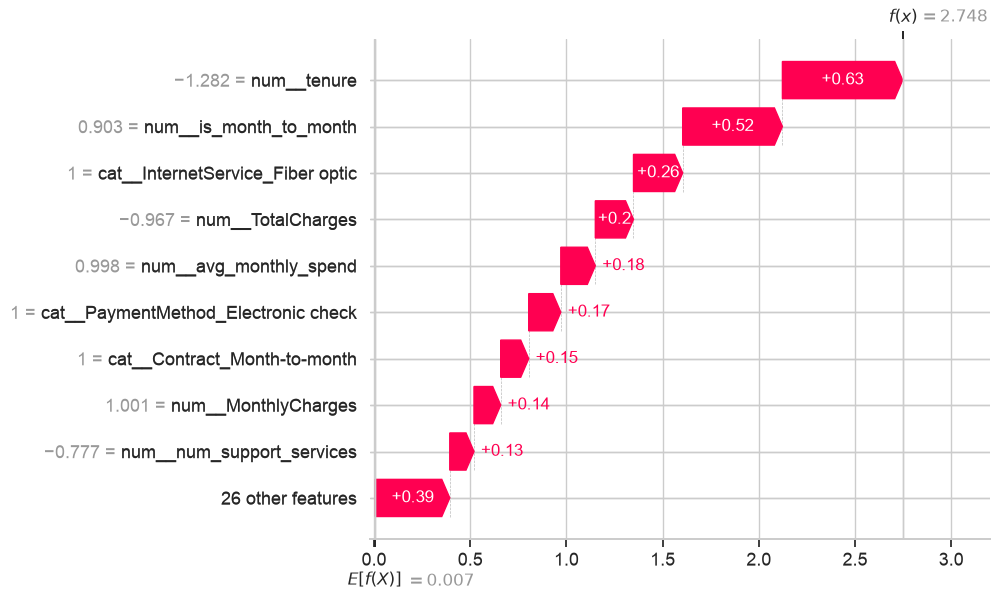

In [19]:
# Why is the single riskiest customer flagged?
i = int(np.argmax(proba))
base_val = float(np.ravel(explainer.expected_value)[0])
shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base_val, data=Xt[i], feature_names=list(names)), max_display=10)

## 10. Save the model and a prediction helper

In [20]:
os.makedirs("models", exist_ok=True)
joblib.dump({"pipeline": best, "threshold": best_th,
             "assumptions": {"cost_offer": COST_OFFER, "value_saved": VALUE_SAVED, "save_rate": SAVE_RATE}},
            "models/churn_model.joblib")

def predict_customers(raw_df, model_path="models/churn_model.joblib"):
    """Takes raw customer rows (same columns as the CSV, no Churn) and returns risk scores."""
    bundle = joblib.load(model_path)
    p = bundle["pipeline"].predict_proba(raw_df)[:, 1]
    out = raw_df.copy()
    out["churn_prob"] = p.round(3)
    out["risk"] = pd.cut(p, [0, 0.3, 0.6, 1.0], labels=["Low", "Medium", "High"], include_lowest=True)
    out["flag_for_retention"] = p >= bundle["threshold"]
    return out

predict_customers(X_test.head(8))[["tenure", "Contract", "MonthlyCharges", "churn_prob", "risk", "flag_for_retention"]]

,tenure,Contract,MonthlyCharges,churn_prob,risk,flag_for_retention
437,72,Two year,114.05,0.101,Low,False
2280,8,Month-to-month,100.15,0.880,High,True
2235,41,One year,78.35,0.226,Low,False
4460,18,Month-to-month,78.20,0.617,High,True
3761,72,Two year,82.65,0.042,Low,False
5748,21,Month-to-month,99.85,0.733,High,True
3568,21,Month-to-month,99.15,0.654,High,True
2976,19,Month-to-month,24.10,0.284,Low,False
